# **Section 9: XGBoost Classification**

In this notebook, I will train and evaluate XGBoost (Gradient Boosting) models. XGBoost is particularly well-suited for high-dimensional genomic data with limited samples. I will start with a baseline model and then tune hyperparameters using cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic decision tree**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
   - 5.1 Load cluster names
   - 5.2 Extract feature importance
   - 5.3 Export biomarkers
6. **Saving model results**


## **1. Importing the Data**

Let's import the data and split it into training, validation and test sets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')
sns.set_palette("pastel")

### **1.1 Load Features**

In [2]:
# Load features and labels
snp_train = pd.read_csv("Data/snp_train_selected.csv", index_col=0)
snp_test = pd.read_csv("Data/snp_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = snp_train.values
y_train = profiles_train.values

X_test = snp_test.values
y_test = profiles_test.values

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (176, 796)
Test set shape: (50, 796)
Categories: [0 1]


## **2. Basic XGBoost model**
### **2.1 Fitting and training the model**
Let's start with a basic XGBoost model using default parameters (n_estimators = 100, max_depth = 5, learning_rate = 0.1, reg_alpha (L1 regularization) = 0, reg_lambda (l2 regularization) = 1)

In [3]:
# Create XGBoost model (no scaling needed for tree-based models)
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=2,
    eval_metric='logloss'
)

# Train the model
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### **2.1 Evaluate Baseline Model**

In [4]:
# Evaluate on training, validation, and test sets
accuracy_train = xgb_model.score(X_train, y_train)
accuracy_test = xgb_model.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.9943
Accuracy test set: 0.4800


### **2.3 Classification Report and Confusion Matrix**

In [5]:
# Get predictions
y_test_pred = xgb_model.predict(X_test)

# Classification report
print("Classification Report (Baseline XGBoost):")
print(classification_report(y_test, y_test_pred))

Classification Report (Baseline XGBoost):
              precision    recall  f1-score   support

           0       0.62      0.33      0.43        30
           1       0.41      0.70      0.52        20

    accuracy                           0.48        50
   macro avg       0.52      0.52      0.48        50
weighted avg       0.54      0.48      0.47        50



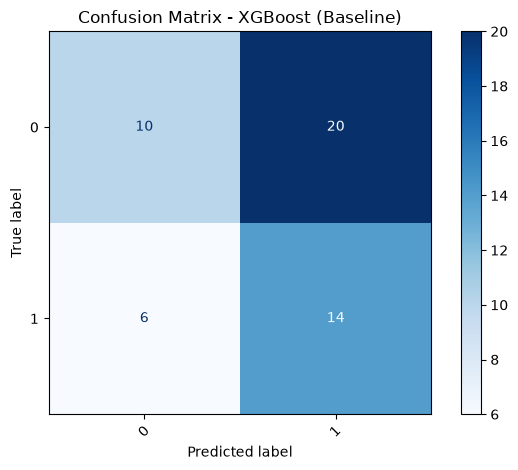

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=xgb_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=xgb_model.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - XGBoost (Baseline)")
plt.tight_layout()
plt.show()

We see that the basic model also doesn't perform well here, as was expected.

## **3. Hyperparameter Tuning**

Now let's use cross-validated grid search to find optimal hyperparameters. We will optimize the max depth of the tree, the learning rate, and L1 and L2 regularization strength.

### **3.1 Grid Search for Optimal Hyperparameters**

In [7]:
# Define parameter grid
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'reg_alpha': [0.0, 0.1],  # L1 regularization
    'reg_lambda': [0.1, 1.0]  # L2 regularization
}

# Create grid search
grid_search = GridSearchCV(
    xgb.XGBClassifier(
        n_estimators=100,
        random_state=4,
        eval_metric='logloss'
    ),
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=1
)

# Perform grid search
print("Performing grid search")
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Performing grid search

Best parameters: {'learning_rate': 0.2, 'max_depth': 5, 'reg_alpha': 0.1, 'reg_lambda': 0.1}
Best cross-validation score: 0.7503


### **3.3 Analyze Grid Search Results**

In [8]:
# Extract results
cv_results = pd.DataFrame(grid_search.cv_results_)

# Display top results
results_display = cv_results[[
    'mean_test_score', 'std_test_score', 
    'mean_train_score', 'std_train_score',
    'param_max_depth', 'param_learning_rate', 'param_reg_alpha', 'param_reg_lambda'
]].sort_values('mean_test_score', ascending=False).head(10)

print("\nTop 10 Grid Search Results:")
print(results_display)


Top 10 Grid Search Results:
    mean_test_score  std_test_score  mean_train_score  std_train_score  \
30         0.750317        0.053498          0.994306         0.005340   
27         0.744603        0.045808          0.994306         0.005340   
32         0.738889        0.035628          0.995735         0.003483   
25         0.727619        0.043685          0.994306         0.005340   
33         0.727619        0.043685          0.994306         0.005340   
28         0.727619        0.059507          0.994316         0.002842   
12         0.716190        0.058212          0.992888         0.004518   
29         0.716190        0.045635          0.994306         0.005340   
22         0.710635        0.058389          0.994306         0.005340   
20         0.710635        0.052500          0.995735         0.003483   

    param_max_depth  param_learning_rate  param_reg_alpha  param_reg_lambda  
30                5                  0.2              0.1               0.1  


### **3.4 Visualize Learning Rate Effect**

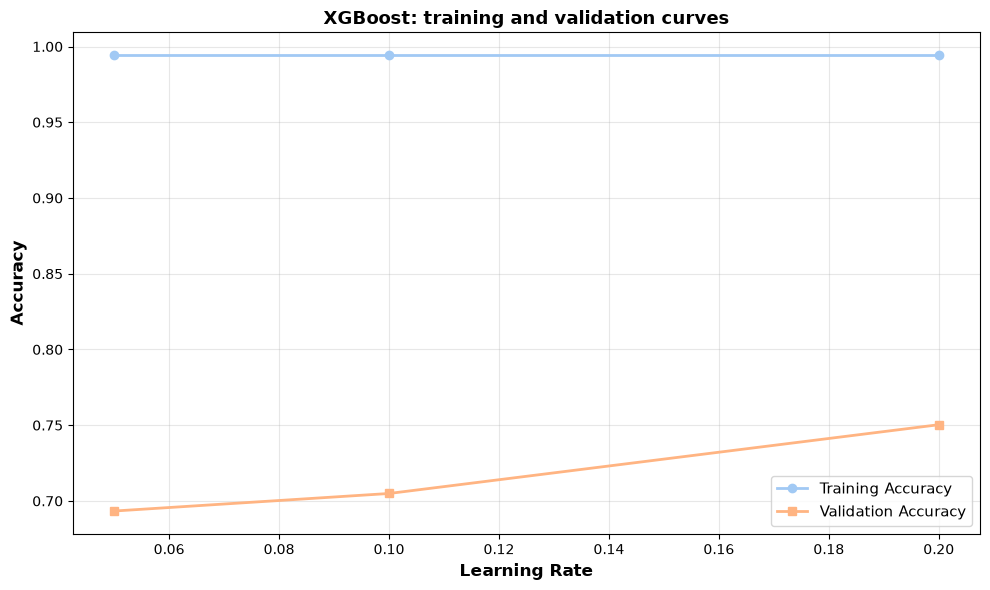

In [15]:
# Filter results for best max_depth
best_max_depth = grid_search.best_params_['max_depth']
best_reg_alpha = grid_search.best_params_['reg_alpha']
best_reg_lambda = grid_search.best_params_['reg_lambda']

filtered_results = cv_results[
    (cv_results['param_max_depth'] == best_max_depth) &
    (cv_results['param_reg_alpha'] == best_reg_alpha) &
    (cv_results['param_reg_lambda'] == best_reg_lambda)
].sort_values('param_learning_rate')

if len(filtered_results) > 0:
    plt.figure(figsize=(10, 6))
    plt.plot(
        filtered_results['param_learning_rate'],
        filtered_results['mean_train_score'],
        label='Training Accuracy',
        marker='o',
        linewidth=2
    )
    plt.plot(
        filtered_results['param_learning_rate'],
        filtered_results['mean_test_score'],
        label='Validation Accuracy',
        marker='s',
        linewidth=2
    )
    
    plt.xlabel('Learning Rate', fontsize=12, fontweight='bold')
    plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
    plt.title('XGBoost: training and validation curves', fontsize=13, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## **4. Evaluate Best Model**
### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_xgb = grid_search.best_estimator_
accuracy_test_best = best_xgb.score(X_test, y_test)

print(f"\nBest Model Test Accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")


Best Model Test Accuracy: 0.4800
Best parameters: {'learning_rate': 0.2, 'max_depth': 5, 'reg_alpha': 0.1, 'reg_lambda': 0.1}
Best CV score: 0.7503


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_xgb.predict(X_test)

# Classification report
print("\nClassification Report (Best XGBoost):")
print(classification_report(y_test, y_test_pred_best))


Classification Report (Best XGBoost):
              precision    recall  f1-score   support

           0       0.64      0.30      0.41        30
           1       0.42      0.75      0.54        20

    accuracy                           0.48        50
   macro avg       0.53      0.53      0.47        50
weighted avg       0.55      0.48      0.46        50



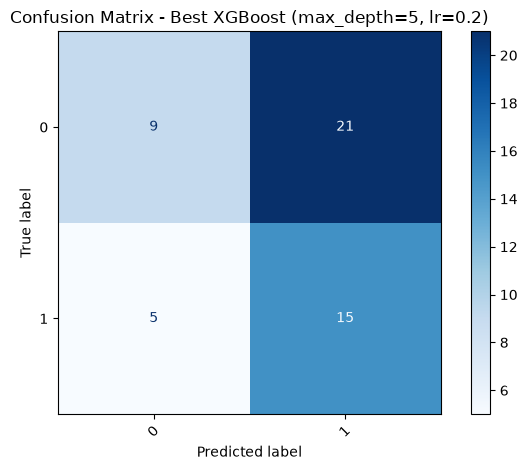

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_xgb.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_xgb.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix - Best XGBoost (max_depth={grid_search.best_params_['max_depth']}, lr={grid_search.best_params_['learning_rate']})")
plt.tight_layout()
plt.show()

### **4.3 ROC curve and AUC score**

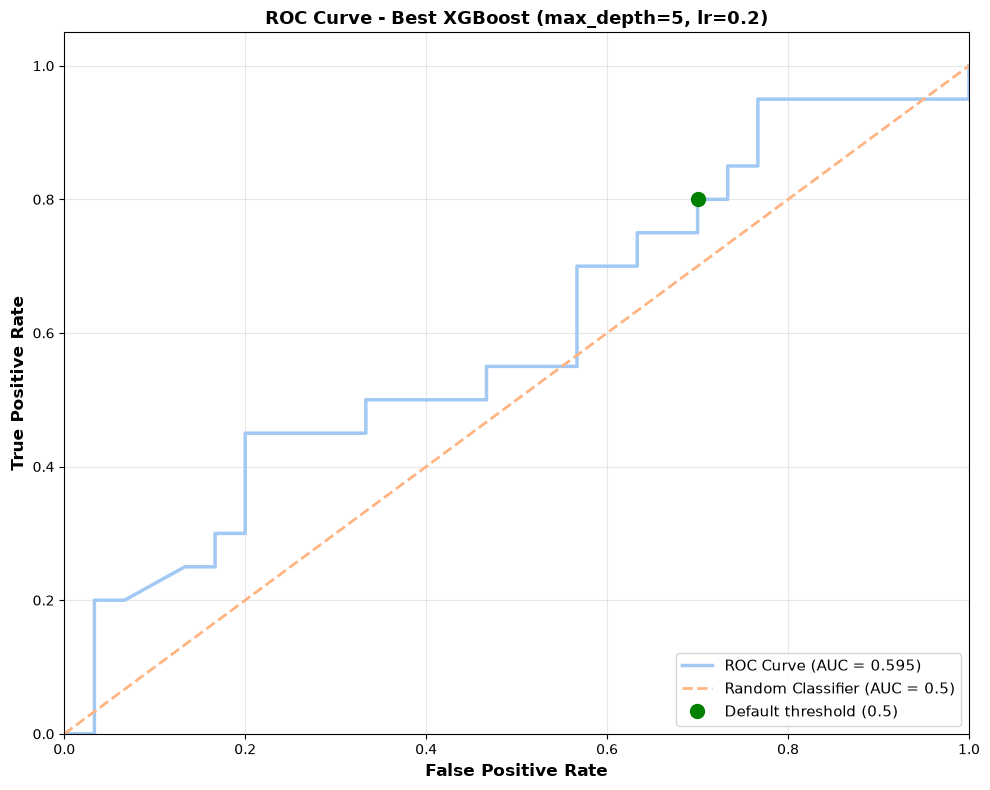


AUC Score: 0.5950
For the default threshold (0.5):
True positive rate: 0.800 (catch 80.0% of resistant)
False positive rate: 0.700 (70.0% of susceptible misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_xgb.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], lw=2, linestyle='--', label='Random Classifier (AUC = 0.5)')

# Mark the default threshold (0.5)
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve - Best XGBoost (max_depth={grid_search.best_params_["max_depth"]}, lr={grid_search.best_params_["learning_rate"]})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"For the default threshold (0.5):")
print(f"True positive rate: {tpr[default_idx]:.3f} (catch {tpr[default_idx]*100:.1f}% of resistant)")
print(f"False positive rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptible misclassified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.

We will identify which features were used by the best decision tree to classify the samples by looking at the gini importance for each feature. We can access this using *best_xgb.feature_importances_*

### **5.1 Get Feature Names**
As before, we don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however, have the names of the clusters, and a list of features associated with each cluster in the file Data/clusters.csv. Let's import the cluster.csv file.

In [16]:
cluster_names = snp_train.columns.values
features_to_cluster = pd.read_csv("Data/clusters.csv")
features_to_cluster.head()

,cluster,snp,cluster_size
0,0,snp__NZ_AP028078.1_1825474_C_T,1
1,1,snp__NZ_AP028077.1_1061328_AGTCGCCGAAGTCGCCGAA...,1
2,2,snp__NZ_AP028077.1_1565260_C_T,1
3,3,snp__NZ_AP028078.1_2219598_T_G,1
4,4,snp__NZ_AP028077.1_72372_G_A,1


### **5.2 Feature Importance**

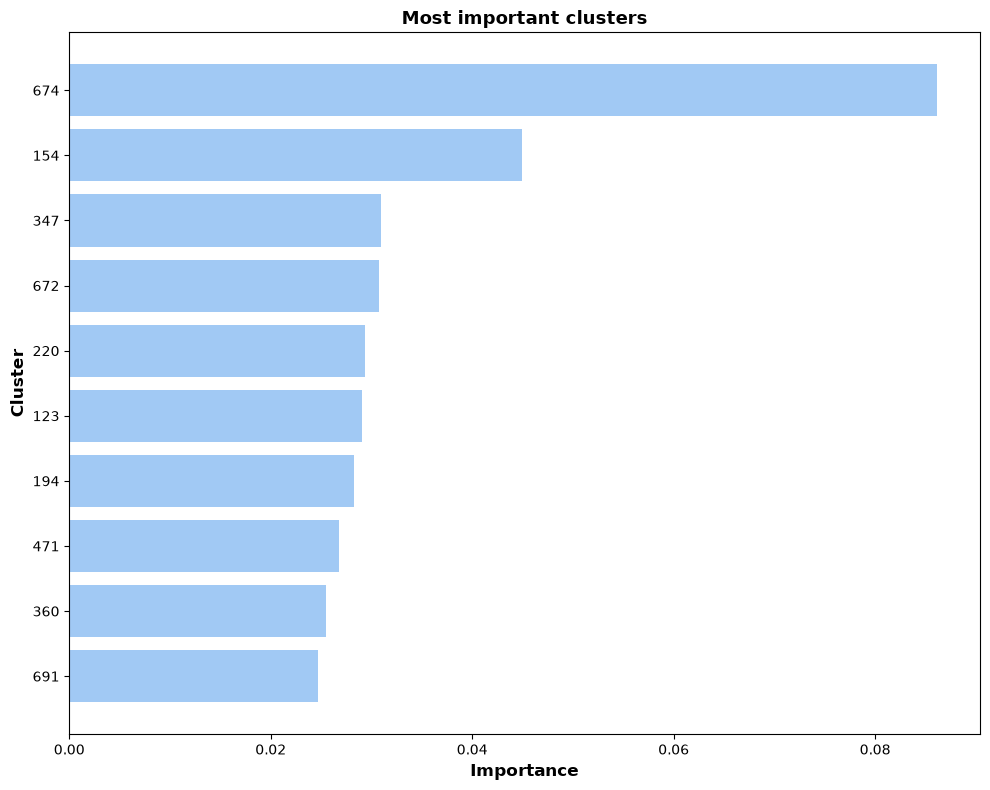

In [17]:
# Get feature importances
feature_importance = best_xgb.feature_importances_
feature_importance_df = pd.DataFrame({
    'cluster': cluster_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

# Plot top 10 features (clusters)
plt.figure(figsize=(10, 8))
plt.barh(range(10), feature_importance_df['importance'].head(10))
plt.yticks(range(10), feature_importance_df['cluster'].head(10))
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.ylabel('Cluster', fontsize=12, fontweight='bold')
plt.title('Most important clusters', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Figures/09_xgb_feature_importance.png", dpi=300)
plt.show()

## **5. Save Results**

In [18]:
import csv
import os

# Store results
results = {
    'model': 'XGBoost',
    'hyperparameters': f"max_depth={grid_search.best_params_['max_depth']}, learning_rate={grid_search.best_params_['learning_rate']}, reg_alpha={grid_search.best_params_['reg_alpha']}, reg_lambda={grid_search.best_params_['reg_lambda']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = 'Results/model_results.csv'

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: XGBoost
Hyperparameters: max_depth=5, learning_rate=0.2, reg_alpha=0.1, reg_lambda=0.1
Test Accuracy: 0.4800
CV Score: 0.7503


In [ ]:
!